# Full-frame NFFA resized-to-128 inpainting

This experiment is an alternative to `nffa_full_raw_random_inpainting.ipynb`. It does **not** split the raw SEM frame into tiles. Instead, it creates a mask at the raw resolution, resizes the complete clean frame to one 128 × 128 model input, resizes the mask with nearest-neighbor interpolation, applies the mask, and runs one PnP-Flow reconstruction.

The reconstruction is evaluated at the model's native 128 × 128 resolution. It is also resized back to the raw-frame dimensions for visualization and missing-region comparison. Upscaling cannot recover spatial detail discarded by the initial downscaling.

Mask convention: `known_mask=True` means observed and data-consistent; `missing_mask=True` means removed and reconstructed.

In [2]:
from pathlib import Path
import csv
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image

repo_root = Path.cwd().resolve()
if not (repo_root / 'pnpflow').is_dir():
    repo_root = repo_root.parent
if not (repo_root / 'pnpflow').is_dir():
    raise RuntimeError('Open this notebook from the PnP-Flow repository or its notebooks/ directory.')
os.chdir(repo_root)

from pnpflow.utils import define_model

# Select a source that belongs to the held-out test split.
DATASET_NAME = 'sem_nffa_all10'
RUN_NAME = '20260713_112747_sem_nffa_all10_ot'
CHECKPOINT_PATH = repo_root / 'model' / DATASET_NAME / 'ot' / RUN_NAME / 'model_final.pt'
RAW_SEM_ROOT = Path('/data2/marci/bselvaku/nffa_sem/raw_images')
SOURCE_MANIFEST_PATH = repo_root / 'data' / DATASET_NAME / 'source_manifest.csv'
TEST_SOURCE_INDEX = 0

with SOURCE_MANIFEST_PATH.open(newline='', encoding='utf-8') as handle:
    test_source_rows = [row for row in csv.DictReader(handle) if row['split'] == 'test']
if not test_source_rows:
    raise RuntimeError(f'No test sources were found in {SOURCE_MANIFEST_PATH}')
if not 0 <= TEST_SOURCE_INDEX < len(test_source_rows):
    raise IndexError(f'TEST_SOURCE_INDEX={TEST_SOURCE_INDEX}; valid range is 0:{len(test_source_rows)}')
RAW_SOURCE_ROW = test_source_rows[TEST_SOURCE_INDEX]
RAW_SOURCE_RELATIVE = Path(RAW_SOURCE_ROW['source'])
RAW_SEM_IMAGE = RAW_SEM_ROOT / RAW_SOURCE_RELATIVE

# Model/inference parameters, matching the reference random-inpainting notebook.
MODEL_SIZE = 128
NOISE_SEED = 0
NOISE_STD = 0.01
STEPS_PNP = 100
NUM_SAMPLES = 5
LR_PNP = 1.0
ALPHA = 0.01
USE_MULTI_GPU = False

# Mask configuration. The mask is first made at raw resolution and is then
# resized to MODEL_SIZE x MODEL_SIZE with nearest-neighbor interpolation.
MASK_MODE = 'square'  # Choose 'square' or 'random'.
SQUARE_SIZE_RAW = 512
SQUARE_BOX_RAW = None  # Optional (top, left, bottom, right); overrides SQUARE_SIZE_RAW.
MISSING_FRACTION = 0.70
MASK_SEED = 42

experiment_name = f'full_raw_resized_{MODEL_SIZE}_{MASK_MODE}_inpainting'
OUTPUT_DIR = repo_root / 'results' / DATASET_NAME / 'ot' / experiment_name / RAW_SEM_IMAGE.stem
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

assert CHECKPOINT_PATH.is_file(), f'Checkpoint not found: {CHECKPOINT_PATH}'
assert RAW_SEM_IMAGE.is_file(), f'Raw SEM image not found: {RAW_SEM_IMAGE}'
print(f'Repository: {repo_root}')
print(f'Checkpoint: {CHECKPOINT_PATH}')
print(f"Manifest split: {RAW_SOURCE_ROW['split']} ({len(test_source_rows):,} available test sources)")
print(f'Raw image: {RAW_SEM_IMAGE}')
print(f'Mask mode: {MASK_MODE}')
print(f'Output directory: {OUTPUT_DIR}')

Repository: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow
Checkpoint: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/model/sem_nffa_all10/ot/20260713_112747_sem_nffa_all10_ot/model_final.pt
Manifest split: test (2,133 available test sources)
Raw image: /data2/marci/bselvaku/nffa_sem/raw_images/Biological/L7_2e35622323b48389237957bcbd0d801d.jpg
Mask mode: square
Output directory: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/full_raw_resized_128_square_inpainting/L7_2e35622323b48389237957bcbd0d801d


In [3]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
if device.type != 'cuda':
    raise RuntimeError('This PnP-Flow benchmark requires a CUDA GPU.')

torch.manual_seed(0)
torch.cuda.manual_seed_all(0)

class ModelArgs:
    model = 'ot'
    num_channels = 1
    dim_image = MODEL_SIZE

model, _ = define_model(ModelArgs())
state_dict = torch.load(CHECKPOINT_PATH, map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.to(device).eval()

# The five prior draws are evaluated as a batch, so DataParallel can distribute
# them. With only one GPU this follows the same inference path on cuda:0.
gpu_ids = list(range(torch.cuda.device_count()))
if USE_MULTI_GPU and len(gpu_ids) > 1:
    model = torch.nn.DataParallel(model, device_ids=gpu_ids, output_device=gpu_ids[0])
    print(f'Multi-GPU prior sampling enabled on {len(gpu_ids)} GPUs: {gpu_ids}')
else:
    print(f'Single-GPU inference on {torch.cuda.get_device_name(0)}')
print(f'Primary device: {device}')

Single-GPU inference on Tesla V100-SXM2-32GB
Primary device: cuda:0


In [4]:
# Load and normalize the complete source exactly as SEM patch preparation does:
# grayscale, source-level 1st/99th percentile clipping, then map to [-1, 1].
with Image.open(RAW_SEM_IMAGE) as image:
    raw_sem = np.asarray(image.convert('L'), dtype=np.float32)
if raw_sem.ndim != 2 or not np.isfinite(raw_sem).all():
    raise ValueError(f'Expected a finite 2D grayscale frame, got {raw_sem.shape}')

height, width = raw_sem.shape
low, high = np.percentile(raw_sem, (1, 99))
if not high > low:
    raise ValueError('The raw frame has no usable percentile intensity range.')
raw_clipped = np.clip(raw_sem, low, high).astype(np.float32)
raw_norm = (2.0 * (raw_clipped - low) / (high - low) - 1.0).astype(np.float32)

# Build the requested missing mask at the original image resolution.
if MASK_MODE == 'square':
    if SQUARE_BOX_RAW is None:
        if not 0 < SQUARE_SIZE_RAW <= min(height, width):
            raise ValueError(
                f'SQUARE_SIZE_RAW={SQUARE_SIZE_RAW} is invalid for raw shape {raw_sem.shape}.'
            )
        raw_top = (height - SQUARE_SIZE_RAW) // 2
        raw_left = (width - SQUARE_SIZE_RAW) // 2
        raw_bottom = raw_top + SQUARE_SIZE_RAW
        raw_right = raw_left + SQUARE_SIZE_RAW
    else:
        raw_top, raw_left, raw_bottom, raw_right = map(int, SQUARE_BOX_RAW)
        if not (0 <= raw_top < raw_bottom <= height and 0 <= raw_left < raw_right <= width):
            raise ValueError(f'SQUARE_BOX_RAW={SQUARE_BOX_RAW} is outside raw shape {raw_sem.shape}.')
    missing_raw = np.zeros(raw_sem.shape, dtype=bool)
    missing_raw[raw_top:raw_bottom, raw_left:raw_right] = True
elif MASK_MODE == 'random':
    if not 0.0 < MISSING_FRACTION < 1.0:
        raise ValueError('MISSING_FRACTION must be between zero and one.')
    mask_rng = np.random.default_rng(MASK_SEED)
    missing_raw = mask_rng.random(raw_sem.shape) < MISSING_FRACTION
else:
    raise ValueError("MASK_MODE must be either 'square' or 'random'.")

def resize_float(array, output_shape, mode='bilinear'):
    tensor = torch.from_numpy(np.asarray(array, dtype=np.float32))[None, None]
    kwargs = {'align_corners': False} if mode in {'linear', 'bilinear', 'bicubic', 'trilinear'} else {}
    return F.interpolate(tensor, size=output_shape, mode=mode, **kwargs)[0, 0].numpy()

# Resize the clean normalized frame and mask separately. Applying the mask only
# after resizing prevents black missing values from bleeding into known pixels.
clean_model = resize_float(raw_norm, (MODEL_SIZE, MODEL_SIZE), mode='bilinear').astype(np.float32)
missing_model = resize_float(
    missing_raw.astype(np.float32), (MODEL_SIZE, MODEL_SIZE), mode='nearest'
) >= 0.5
known_model = ~missing_model
if not missing_model.any():
    raise RuntimeError('The mask disappeared during resizing; enlarge the raw mask.')
if missing_model.all():
    raise RuntimeError('The resized mask covers the complete model input and leaves no observed pixels.')

noise_rng = np.random.default_rng(NOISE_SEED)
known_noise = noise_rng.normal(0.0, NOISE_STD, clean_model.shape).astype(np.float32)
observed_model = np.zeros_like(clean_model, dtype=np.float32)
observed_model[known_model] = np.clip(
    clean_model[known_model] + known_noise[known_model], -1.0, 1.0
)

def denormalize(image_norm):
    return np.clip((image_norm + 1.0) * 0.5 * (high - low) + low, low, high)

observed_raw_display = raw_clipped.copy()
observed_raw_display[missing_raw] = 0.0
observed_model_display = denormalize(observed_model)
observed_model_display[missing_model] = 0.0

missing_rows, missing_cols = np.where(missing_model)
model_mask_bounds = (
    int(missing_rows.min()), int(missing_cols.min()),
    int(missing_rows.max() + 1), int(missing_cols.max() + 1),
)
model_mask_height = model_mask_bounds[2] - model_mask_bounds[0]
model_mask_width = model_mask_bounds[3] - model_mask_bounds[1]

print(f'Raw frame: Y={height}, X={width}')
print(f'Normalization percentiles: low={low:.5g}, high={high:.5g}')
print(f'Raw missing pixels: {missing_raw.sum():,}/{missing_raw.size:,} ({missing_raw.mean():.2%})')
print(f'Resized model input: {clean_model.shape}')
print(f'Resized missing pixels: {missing_model.sum():,}/{missing_model.size:,} ({missing_model.mean():.2%})')
print(
    f'Resized mask bounds: rows {model_mask_bounds[0]}:{model_mask_bounds[2]}, '
    f'columns {model_mask_bounds[1]}:{model_mask_bounds[3]} '
    f'({model_mask_height} x {model_mask_width} pixels)'
)

Raw frame: Y=768, X=1024
Normalization percentiles: low=67, high=255
Raw missing pixels: 262,144/786,432 (33.33%)
Resized model input: (128, 128)
Resized missing pixels: 5,440/16,384 (33.20%)
Resized mask bounds: rows 22:107, columns 32:96 (85 x 64 pixels)


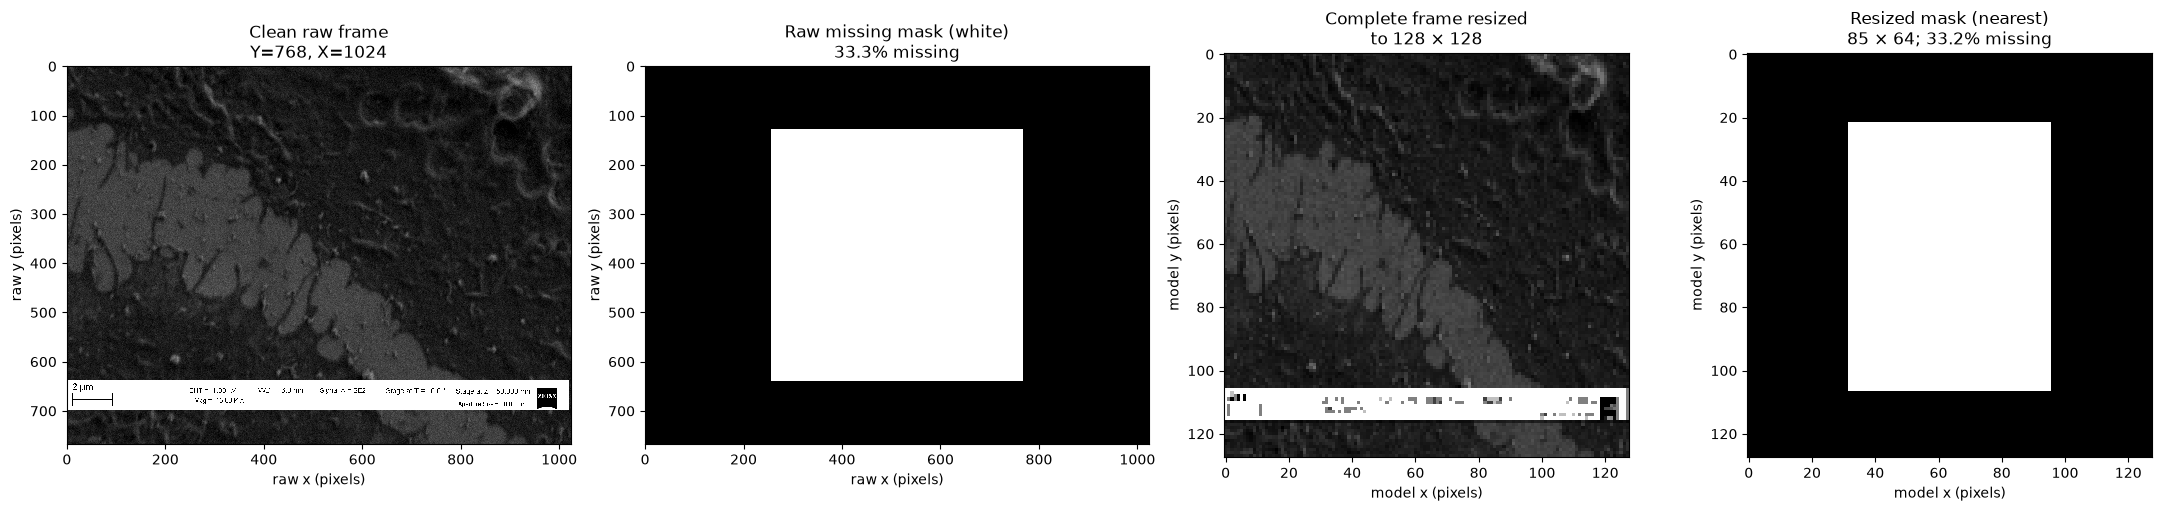

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/full_raw_resized_128_square_inpainting/L7_2e35622323b48389237957bcbd0d801d/raw_to_128_resize_and_mask_diagnostic.png


In [5]:
# Show exactly how the raw frame and its mask map into the one 128 x 128 input.
fig, axes = plt.subplots(1, 4, figsize=(22, 5), constrained_layout=True)
axes[0].imshow(raw_sem, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[0].set_title(f'Clean raw frame\nY={height}, X={width}')
axes[1].imshow(missing_raw, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
axes[1].set_title(f'Raw missing mask (white)\n{missing_raw.mean():.1%} missing')
axes[2].imshow(denormalize(clean_model), cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[2].set_title(f'Complete frame resized\nto {MODEL_SIZE} × {MODEL_SIZE}')
axes[3].imshow(missing_model, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
axes[3].set_title(
    f'Resized mask (nearest)\n{model_mask_height} × {model_mask_width}; '
    f'{missing_model.mean():.1%} missing'
)
for axis in axes[:2]:
    axis.set_xlabel('raw x (pixels)')
    axis.set_ylabel('raw y (pixels)')
for axis in axes[2:]:
    axis.set_xlabel('model x (pixels)')
    axis.set_ylabel('model y (pixels)')
diagnostic_path = OUTPUT_DIR / 'raw_to_128_resize_and_mask_diagnostic.png'
fig.savefig(diagnostic_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {diagnostic_path}')

In [6]:
@torch.inference_mode()
def pnp_flow_inpaint_single(observed, known):
    """Run the reference Gaussian fixed-mask PnP update on one 128 x 128 input."""
    known = known.to(device=observed.device, dtype=observed.dtype)
    x = known * observed
    lr = NOISE_STD ** 2 * LR_PNP

    for iteration in range(STEPS_PNP):
        t = torch.full((1,), iteration / STEPS_PNP, device=observed.device)
        t_view = t.view(1, 1, 1, 1)
        lr_t = lr * (1.0 - t).pow(ALPHA).view(1, 1, 1, 1)

        data_gradient = known * (known * x - observed) / (NOISE_STD ** 2)
        z = x - lr_t * data_gradient

        # Evaluate all stochastic prior draws in one batch. This is equivalent
        # to the reference loop followed by averaging and enables multi-GPU use.
        t_samples = t.expand(NUM_SAMPLES)
        t_samples_view = t_samples.view(NUM_SAMPLES, 1, 1, 1)
        z_samples = z.expand(NUM_SAMPLES, -1, -1, -1)
        z_tilde = (
            t_samples_view * z_samples
            + (1.0 - t_samples_view) * torch.randn_like(z_samples)
        )
        velocity = model(z_tilde, t_samples)
        prior_predictions = z_tilde + (1.0 - t_samples_view) * velocity
        x_new = prior_predictions.mean(dim=0, keepdim=True)

        # Preserve every observed 128-space pixel exactly.
        x = known * observed + (1.0 - known) * x_new

    return x.clamp(-1.0, 1.0)

observed_tensor = torch.from_numpy(observed_model[None, None]).float().to(device)
known_tensor = torch.from_numpy(known_model[None, None].astype(np.float32)).to(device)

inference_start = time.perf_counter()
reconstruction_model = pnp_flow_inpaint_single(observed_tensor, known_tensor).cpu().numpy()[0, 0]
inference_seconds = time.perf_counter() - inference_start
known_consistency = float(np.max(np.abs(reconstruction_model[known_model] - observed_model[known_model])))

print(f'One {MODEL_SIZE} × {MODEL_SIZE} inference completed in {inference_seconds:.2f} s')
print(f'Maximum resized known-pixel consistency error: {known_consistency:.3e}')

One 128 × 128 inference completed in 8.05 s
Maximum resized known-pixel consistency error: 0.000e+00


In [7]:
# Resize the 128 x 128 result back to the raw dimensions. The final native-size
# comparison preserves clean raw pixels outside the synthetic missing mask and
# uses only the upscaled PnP prediction inside it.
reconstruction_upsampled_norm = resize_float(
    reconstruction_model, (height, width), mode='bilinear'
).astype(np.float32)
reconstruction_native_norm = raw_norm.copy()
reconstruction_native_norm[missing_raw] = reconstruction_upsampled_norm[missing_raw]
reconstruction_native_raw = denormalize(reconstruction_native_norm).astype(np.float32)

clean_model_01 = (clean_model + 1.0) * 0.5
observed_model_01 = (observed_model + 1.0) * 0.5
reconstruction_model_01 = (reconstruction_model + 1.0) * 0.5
raw_01 = (raw_norm + 1.0) * 0.5
reconstruction_native_01 = (reconstruction_native_norm + 1.0) * 0.5

def masked_psnr(reference, estimate, mask):
    mse = np.mean((reference[mask] - estimate[mask]) ** 2)
    return float(10.0 * np.log10(1.0 / max(float(mse), 1e-12)))

metrics = {
    'raw_image': str(RAW_SEM_IMAGE),
    'source_relative_path': RAW_SOURCE_RELATIVE.as_posix(),
    'source_split': RAW_SOURCE_ROW['split'],
    'raw_height': int(height),
    'raw_width': int(width),
    'model_size': MODEL_SIZE,
    'mask_mode': MASK_MODE,
    'raw_missing_fraction': float(missing_raw.mean()),
    'resized_missing_fraction': float(missing_model.mean()),
    'resized_mask_height': int(model_mask_height),
    'resized_mask_width': int(model_mask_width),
    'steps_pnp': STEPS_PNP,
    'num_samples': NUM_SAMPLES,
    'alpha': ALPHA,
    'noise_std': NOISE_STD,
    'inference_seconds': float(inference_seconds),
    'resized_observed_missing_psnr_db': masked_psnr(
        clean_model_01, observed_model_01, missing_model
    ),
    'resized_reconstruction_missing_psnr_db': masked_psnr(
        clean_model_01, reconstruction_model_01, missing_model
    ),
    'native_upsampled_reconstruction_missing_psnr_db': masked_psnr(
        raw_01, reconstruction_native_01, missing_raw
    ),
    'maximum_resized_known_consistency_error': known_consistency,
}
if MASK_MODE == 'square':
    metrics['raw_square_box'] = [raw_top, raw_left, raw_bottom, raw_right]

for key, value in metrics.items():
    print(f'{key}: {value}')

np.save(OUTPUT_DIR / 'clean_raw_float32.npy', raw_sem.astype(np.float32))
np.save(OUTPUT_DIR / 'missing_mask_raw_uint8.npy', missing_raw.astype(np.uint8))
np.save(OUTPUT_DIR / 'clean_resized_128_normalized_float32.npy', clean_model.astype(np.float32))
np.save(OUTPUT_DIR / 'observed_resized_128_normalized_float32.npy', observed_model.astype(np.float32))
np.save(OUTPUT_DIR / 'missing_mask_resized_128_uint8.npy', missing_model.astype(np.uint8))
np.save(OUTPUT_DIR / 'reconstruction_resized_128_normalized_float32.npy', reconstruction_model.astype(np.float32))
np.save(OUTPUT_DIR / 'reconstruction_native_size_float32.npy', reconstruction_native_raw)
with (OUTPUT_DIR / 'metrics.json').open('w', encoding='utf-8') as handle:
    json.dump(metrics, handle, indent=2)
print(f'Saved arrays and metrics to: {OUTPUT_DIR}')

raw_image: /data2/marci/bselvaku/nffa_sem/raw_images/Biological/L7_2e35622323b48389237957bcbd0d801d.jpg
source_relative_path: Biological/L7_2e35622323b48389237957bcbd0d801d.jpg
source_split: test
raw_height: 768
raw_width: 1024
model_size: 128
mask_mode: square
raw_missing_fraction: 0.3333333333333333
resized_missing_fraction: 0.33203125
resized_mask_height: 85
resized_mask_width: 64
steps_pnp: 100
num_samples: 5
alpha: 0.01
noise_std: 0.01
inference_seconds: 8.052072423510253
resized_observed_missing_psnr_db: 9.1671896337952
resized_reconstruction_missing_psnr_db: 23.863863932682744
native_upsampled_reconstruction_missing_psnr_db: 21.93728409312477
maximum_resized_known_consistency_error: 0.0
raw_square_box: [128, 256, 640, 768]
Saved arrays and metrics to: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/full_raw_resized_128_square_inpainting/L7_2e35622323b48389237957bcbd0d801d


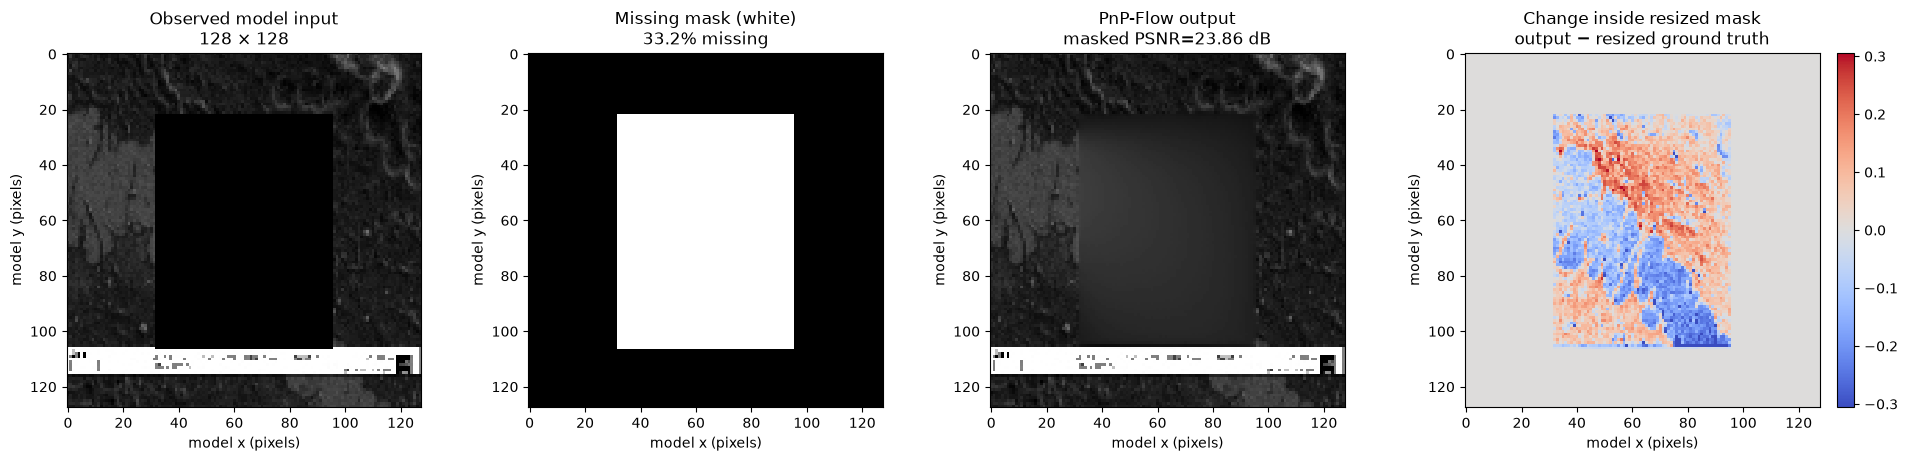

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/full_raw_resized_128_square_inpainting/L7_2e35622323b48389237957bcbd0d801d/resized_128_four_panel_comparison.png


In [8]:
# Four-panel comparison at the actual model resolution.
model_change = np.zeros_like(clean_model, dtype=np.float32)
model_change[missing_model] = reconstruction_model[missing_model] - clean_model[missing_model]
model_change_limit = max(float(np.percentile(np.abs(model_change[missing_model]), 99)), 1e-6)

fig, axes = plt.subplots(1, 4, figsize=(19, 4.5), constrained_layout=True)
axes[0].imshow(observed_model_display, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[0].set_title(f'Observed model input\n{MODEL_SIZE} × {MODEL_SIZE}')
axes[1].imshow(missing_model, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
axes[1].set_title(f'Missing mask (white)\n{missing_model.mean():.1%} missing')
axes[2].imshow(denormalize(reconstruction_model), cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[2].set_title(
    'PnP-Flow output\n'
    f"masked PSNR={metrics['resized_reconstruction_missing_psnr_db']:.2f} dB"
)
change_plot = axes[3].imshow(
    model_change, cmap='coolwarm', vmin=-model_change_limit, vmax=model_change_limit,
    interpolation='nearest',
)
axes[3].set_title('Change inside resized mask\noutput − resized ground truth')
fig.colorbar(change_plot, ax=axes[3], fraction=0.046, pad=0.04)
for axis in axes:
    axis.set_xlabel('model x (pixels)')
    axis.set_ylabel('model y (pixels)')
model_comparison_path = OUTPUT_DIR / 'resized_128_four_panel_comparison.png'
fig.savefig(model_comparison_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {model_comparison_path}')

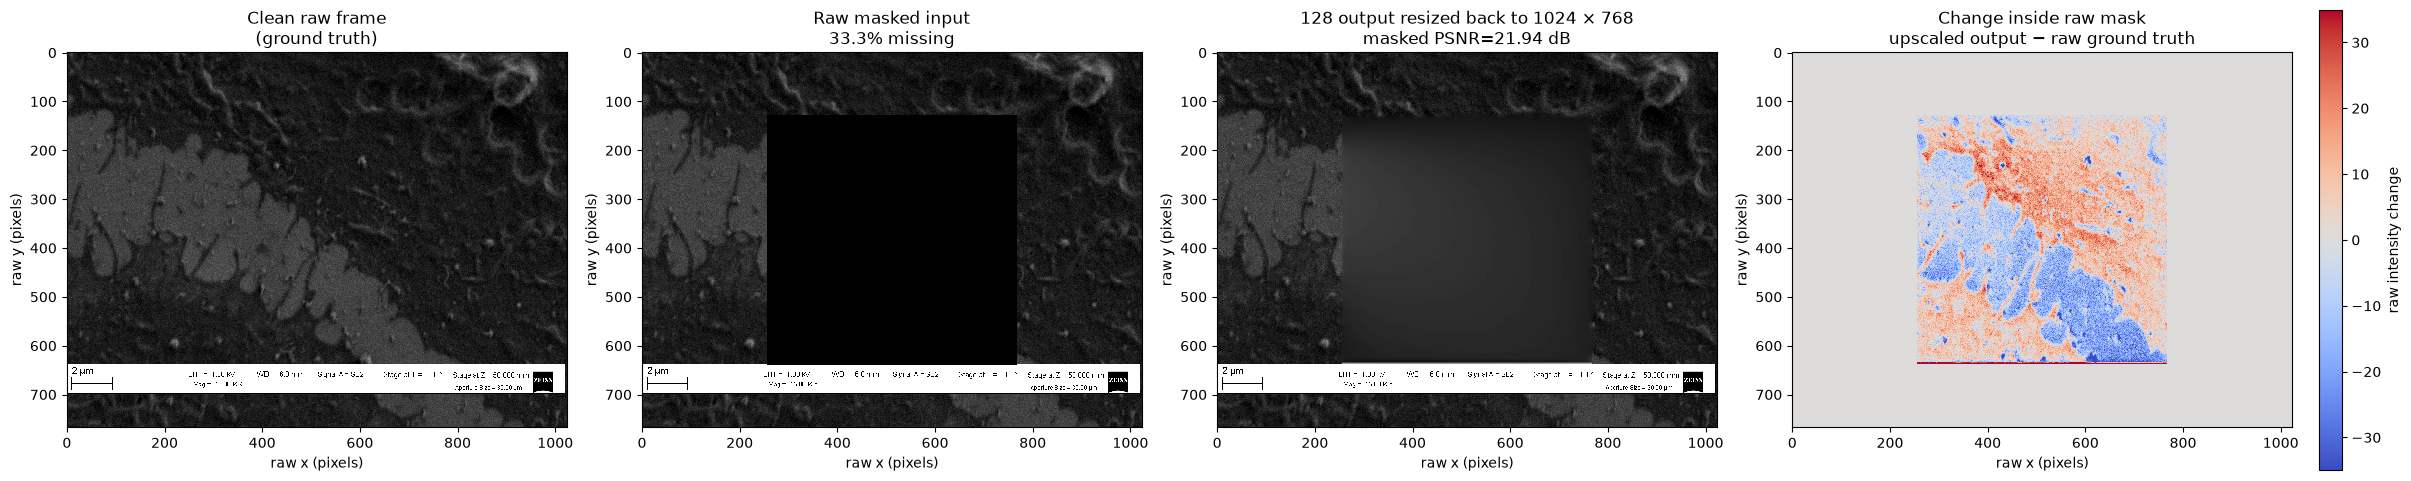

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/full_raw_resized_128_square_inpainting/L7_2e35622323b48389237957bcbd0d801d/native_size_four_panel_comparison.png


In [9]:
# Native-size visualization after upscaling the single model result.
native_change = np.zeros_like(raw_norm, dtype=np.float32)
native_change[missing_raw] = reconstruction_native_raw[missing_raw] - raw_clipped[missing_raw]
native_change_limit = max(float(np.percentile(np.abs(native_change[missing_raw]), 99)), 1e-6)

fig, axes = plt.subplots(1, 4, figsize=(24, 6), constrained_layout=True)
axes[0].imshow(raw_sem, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[0].set_title('Clean raw frame\n(ground truth)')
axes[1].imshow(observed_raw_display, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[1].set_title(f'Raw masked input\n{missing_raw.mean():.1%} missing')
axes[2].imshow(reconstruction_native_raw, cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[2].set_title(
    f'{MODEL_SIZE} output resized back to {width} × {height}\n'
    f"masked PSNR={metrics['native_upsampled_reconstruction_missing_psnr_db']:.2f} dB"
)
change_plot = axes[3].imshow(
    native_change, cmap='coolwarm', vmin=-native_change_limit, vmax=native_change_limit,
    interpolation='nearest',
)
axes[3].set_title('Change inside raw mask\nupscaled output − raw ground truth')
fig.colorbar(change_plot, ax=axes[3], fraction=0.046, pad=0.04, label='raw intensity change')
for axis in axes:
    axis.set_xlabel('raw x (pixels)')
    axis.set_ylabel('raw y (pixels)')
native_comparison_path = OUTPUT_DIR / 'native_size_four_panel_comparison.png'
fig.savefig(native_comparison_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {native_comparison_path}')

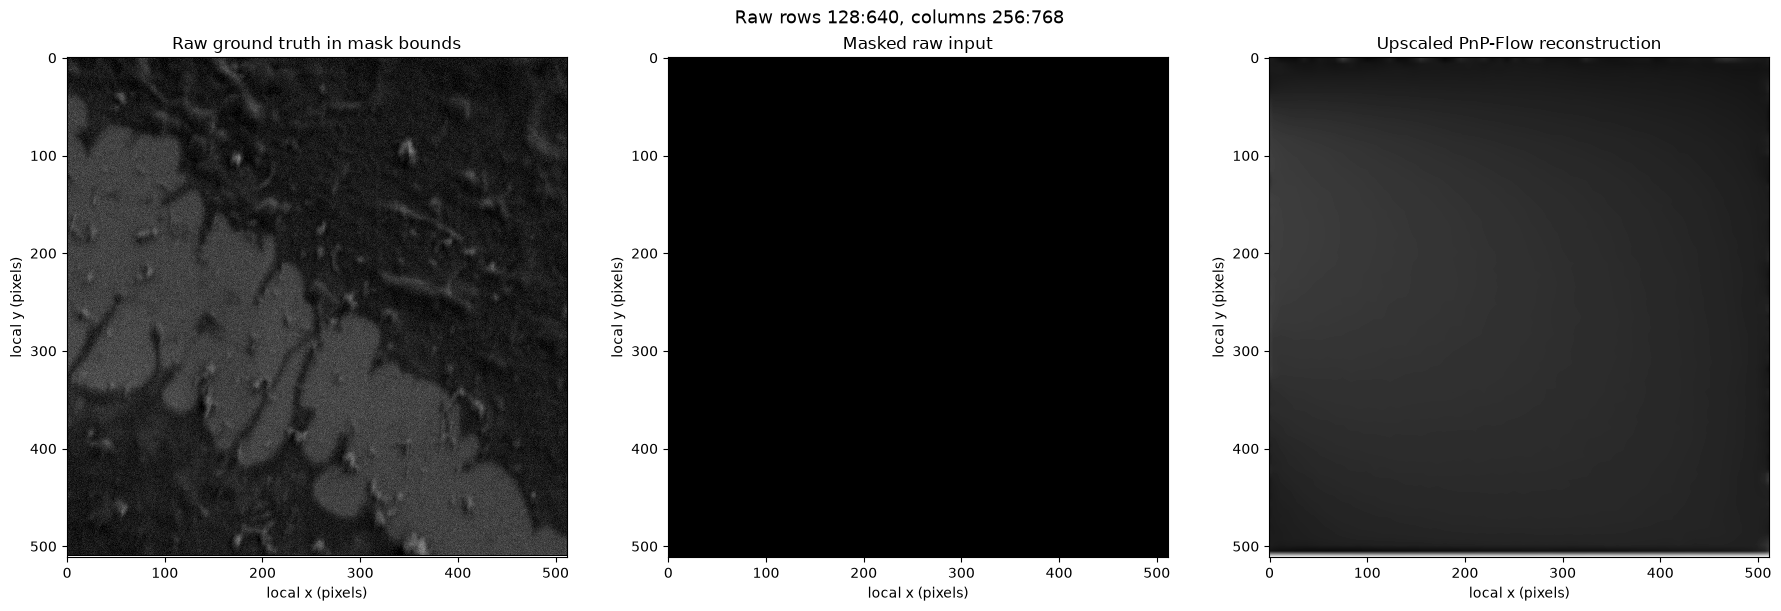

Saved: /home/bselvaku/projects/microscopic_inpainting/modified_code/PnP-Flow/results/sem_nffa_all10/ot/full_raw_resized_128_square_inpainting/L7_2e35622323b48389237957bcbd0d801d/native_missing_region_zoom_comparison.png


: 

In [ ]:
# Zoom into the raw missing-region bounds. For a random mask, use the complete
# frame because the missing pixels are distributed everywhere.
if MASK_MODE == 'square':
    zoom_top, zoom_left, zoom_bottom, zoom_right = raw_top, raw_left, raw_bottom, raw_right
else:
    zoom_top, zoom_left, zoom_bottom, zoom_right = 0, 0, height, width
zoom = np.s_[zoom_top:zoom_bottom, zoom_left:zoom_right]

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
axes[0].imshow(raw_clipped[zoom], cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[0].set_title('Raw ground truth in mask bounds')
axes[1].imshow(observed_raw_display[zoom], cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[1].set_title('Masked raw input')
axes[2].imshow(reconstruction_native_raw[zoom], cmap='gray', vmin=low, vmax=high, interpolation='nearest')
axes[2].set_title('Upscaled PnP-Flow reconstruction')
for axis in axes:
    axis.set_xlabel('local x (pixels)')
    axis.set_ylabel('local y (pixels)')
fig.suptitle(
    f'Raw rows {zoom_top}:{zoom_bottom}, columns {zoom_left}:{zoom_right}', fontsize=13
)
zoom_path = OUTPUT_DIR / 'native_missing_region_zoom_comparison.png'
fig.savefig(zoom_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {zoom_path}')

## Interpretation

This experiment gives the model global image context in one call and avoids independent tile seams or fully missing interior tiles. The cost is severe loss of spatial resolution: every feature in the raw frame is compressed into 128 × 128 pixels before inference. A square mask on a non-square raw frame also becomes rectangular because the full frame is resized anisotropically to a square. The native-size output is therefore a bilinearly upscaled 128 × 128 prediction, not a native-resolution reconstruction.